In [ ]:
#importing
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%store -r model_e X y monza
print(monza)

                       Rettifilo_min_speed  Rettifilo_exit_speed  \
session completedLaps                                              
1       5                        64.864954            120.148296   
        6                        63.819803            131.560845   
        9                        52.487254            131.181325   
        12                       46.796174            128.613419   
        14                       63.439513            130.738285   
2       1                        45.883944            127.045503   
        5                        49.772368            126.236040   
        7                        49.682015            129.766464   
        8                        55.403060            133.633434   
        9                        52.975267            132.030350   
3       1                        53.325133            129.754855   
        2                        57.370324            130.630146   
        3                        52.025585      

                       Rettifilo_min_speed  Rettifilo_exit_speed  \
session completedLaps                                              
4       12                       52.670451            131.651994   

                       Rettifilo_mean_speed  Rettifilo_mean_gas  \
session completedLaps                                             
4       12                       143.918541            0.432974   

                       Rettifilo_mean_brake  Roggia_min_speed  \
session completedLaps                                           
4       12                         0.471332         78.885084   

                       Roggia_exit_speed  Roggia_mean_speed  Roggia_mean_gas  \
session completedLaps                                                          
4       12                    114.405758         176.621576         0.566003   

                       Roggia_mean_brake  ...  Ascari_min_speed  \
session completedLaps                     ...                     
4       12            

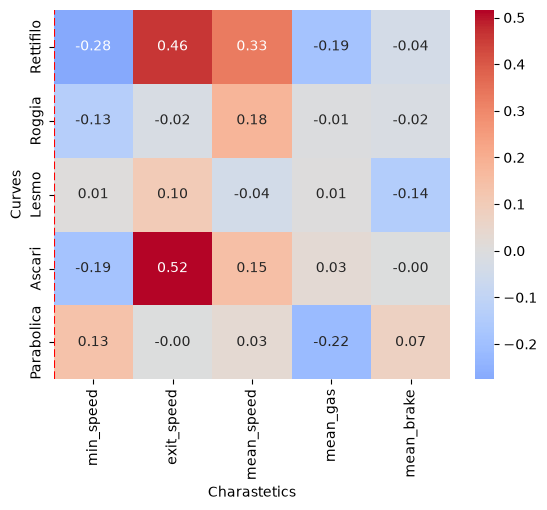

In [ ]:
#we take the best lap done and compare it to random lap chosen from clean telemtry than model gives out where the best lap is faster and when the chosen lap is faster based on that we do heatmap
best_lap = X.loc[[y.idxmin()]]
user_lap = X.loc[[(1,5)]]
print(best_lap , user_lap)
base_time = model_e.predict(user_lap)[0]
gains = {}
for col in monza.keys():
    test_lap = user_lap.copy()
    test_lap[col] = best_lap[col].values
    new_time = model_e.predict(test_lap)[0]
    gains[col] = base_time - new_time
raport = pd.Series(gains).sort_values(ascending=False)
tabela = pd.DataFrame(
    np.array(list(gains.values())).reshape(5, 5),
    index=["Rettifilo", "Roggia", "Lesmo", "Ascari", "Parabolica"],
    columns=["min_speed", "exit_speed", "mean_speed", "mean_gas", "mean_brake"]
)
sns.heatmap(tabela, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.xlabel("Charastetics")
plt.ylabel("Curves")
plt.axvline(0, color="red", linestyle="--")
plt.show()
